# F-JEPA : 4 fois plus de pannes étiquetées, en étiquetant la flotte (données SYNTHÉTIQUES)

> ⚠️ **Données inventées** (voir `generation_capteurs_4ans.ipynb` et `input/capteurs_4ans/flotte_non_etiquetee/LISEZMOI_FLOTTE.md`). Rien ici ne démontre quoi que ce soit sur les machines réelles.

**Pourquoi ce notebook.** Dans `F-JEPA_flotte.ipynb`, 12 machines de plus *sans étiquettes* n'ont pas rendu le pré-entraînement utile. Antoine demande maintenant **plus de pannes étiquetées**.

Une précision d'abord : le pré-entraînement JEPA (comme celui de l'autoencodeur) **n'utilise aucune étiquette**. Ajouter des pannes étiquetées ne change donc pas les encodeurs pré-entraînés. Cela peut changer deux choses :
- les **têtes supervisées** (sonde et fine-tuning), qui apprennent sur 4 fois plus de pannes ;
- la **fiabilité de la comparaison** : un test sur 16 machines au lieu de 4, donc des intervalles plus serrés.

**Ce qui change par rapport au notebook précédent** : les 487 dégradations déjà simulées sur la flotte M5 à M16 (jusqu'ici cachées) servent d'étiquettes. Aucune donnée n'est régénérée et les encodeurs pré-entraînés sont repris tels quels (`results_flotte/`, `results_capteurs_4ans/`).

| Étiquettes d'entraînement | Pannes ou ralentissements (sept. 2022 → août 2024) |
|---|---|
| **4 machines** (M1 à M4), comme avant | 62 |
| **16 machines** (M1 à M16) | 62 + celles de la flotte (voir section 3) |

**Question posée** (inchangée) : toutes les 2 h, *« panne ou ralentissement dans les 7 jours ? »* à partir des 24 dernières heures. Validation sept. 2024 → août 2025 (sur les machines étiquetées), test sept. 2025 → août 2026 :
- **test M1–M4** : le même que dans les notebooks précédents (comparaison directe) ;
- **test M1–M16** : 4 fois plus grand, intervalles plus serrés. Avec les étiquettes des 16 machines, les modèles ont vu des pannes de M5 à M16 *pendant l'entraînement* (années différentes) : c'est le cas d'une usine qui qualifie les pannes de toute sa flotte.

**Plan** : 0. paramètres · 1. chargement · 2. tokens · 3. cible et jeux d'étiquettes · 4. baseline experte · 5. encodeurs · 6. sondes · 7. fine-tuning · 8. résultats · 9. hypothèses et conclusions

## 0. Paramètres

In [1]:
import os, time, json, math, warnings, pickle
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import lfilter
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
warnings.filterwarnings("ignore", message="enable_nested_tensor")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

DATA_DIR = Path(os.environ.get("FJEPA_DATA", "../input/capteurs_4ans"))
FLOTTE_DIR = DATA_DIR / "flotte_non_etiquetee"
RES = Path(os.environ.get("FJEPA_RES", "results_flotte_etiquetee")); RES.mkdir(exist_ok=True)
RES_4ANS = Path(os.environ.get("FJEPA_RES_4ANS", "results_capteurs_4ans"))      # poids JEPA-4 / autoencodeur-4
RES_FLOTTE = Path(os.environ.get("FJEPA_RES_FLOTTE", "results_flotte"))         # poids JEPA-16 / autoencodeur-16 et fine-tunings sur 4 machines
SEEDS = [int(x) for x in os.environ.get("FJEPA_SEEDS", "0,1,2").split(",")]
FT_EPOCHS = int(os.environ.get("FJEPA_FT_EPOCHS", "6")); FT_STEPS = int(os.environ.get("FJEPA_FT_STEPS", "150"))
ENC_NAMES = os.environ.get("FJEPA_ENCODERS", "Aléatoire,JEPA-4,Autoencodeur-4,JEPA-16,Autoencodeur-16").split(",")
for s_ in SEEDS:
    for f_ in [RES_4ANS / f"jepa_seed{s_}.pt", RES_4ANS / f"autoencodeur_seed{s_}.pt", RES_FLOTTE / f"jepa16_seed{s_}.pt", RES_FLOTTE / f"autoencodeur16_seed{s_}.pt"]:
        assert f_.exists(), f"introuvable : {f_.resolve()}"
assert (RES_FLOTTE / "fine_tuning.pkl").exists(), "fine-tunings sur 4 machines du notebook F-JEPA_flotte introuvables"
CONFIG_FT = dict(ft_epochs=FT_EPOCHS, steps=FT_STEPS, batch=128)     # enregistrée avec les fine-tunings : pas de réutilisation si elle change
print("Données :", DATA_DIR, "| résultats :", RES, "| encodeurs :", RES_4ANS, "et", RES_FLOTTE)

CH = ["speed", "temp_ambiante_c", "temp_moteur_c", "temp_palier_c", "vibration_mm_s", "courant_a", "pression_bar"]
SENS = ["temp_moteur_c", "temp_palier_c", "vibration_mm_s", "courant_a", "pression_bar"]
TYPES = ["refroidissement", "roulement", "courroie", "pneumatique", "electrique"]
TOKM, WIN, STRIDE = 15, 96, 8      # token = 15 min ; fenêtre = 24 h ; une prédiction toutes les 2 h
HOR = 7 * 1440; POST_REPAIR = 2 * 1440; MIN_RUN = 120
TRAIN_END, VAL_END = pd.Timestamp("2024-09-01"), pd.Timestamp("2025-09-01")
MACH = ["M1", "M2", "M3", "M4"]; FLOTTE = [f"M{k}" for k in range(5, 17)]; ALL = MACH + FLOTTE
LABELS = {"4": MACH, "16": ALL}     # machines dont les pannes sont étiquetées
torch.set_num_threads(os.cpu_count())
t_start = time.time()

Données : ../input/capteurs_4ans | résultats : results_flotte_etiquetee | encodeurs : results_capteurs_4ans et results_flotte


## 1. Chargement

Les 16 machines sur 4 ans, et la vérité terrain des 16 machines, qui sert maintenant d'étiquettes (M1 à M4 : `verite_terrain_degradations.csv` ; M5 à M16 : `flotte_non_etiquetee/verite_terrain_flotte.csv`).

In [2]:
USE = ["timestamp", "running"] + CH
def load(m):
    files = sorted(DATA_DIR.glob(f"capteurs_{m}_*.csv.gz")) if m in MACH else [FLOTTE_DIR / f"capteurs_{m}_{y}-{y + 1}.csv.gz" for y in range(2022, 2026)]
    return pd.concat([pd.read_csv(f, parse_dates=["timestamp"], usecols=USE) for f in files], ignore_index=True)

cols = ["machine", "type", "issue", "debut_degradation", "evenement", "fin_intervention"]
deg = pd.concat([pd.read_csv(DATA_DIR / "verite_terrain_degradations.csv", parse_dates=cols[3:])[cols],
                 pd.read_csv(FLOTTE_DIR / "verite_terrain_flotte.csv", parse_dates=cols[3:])[cols]], ignore_index=True)
ev = deg[deg.issue != "preventif"].sort_values(["machine", "evenement"])
tab = ev.assign(periode=np.where(ev.evenement < TRAIN_END, "train", np.where(ev.evenement < VAL_END, "val", "test")),
                groupe=np.where(ev.machine.isin(MACH), "M1–M4", "M5–M16")).groupby(["groupe", "periode"]).size().unstack()[["train", "val", "test"]]
print("Pannes ou ralentissements par période :"); print(tab)

Pannes ou ralentissements par période :
periode  train  val  test
groupe                   
M1–M4       62   35    36
M5–M16     200  103   106


## 2. Tokens et caractéristiques expertes

Identiques aux notebooks précédents, calculés machine par machine (normalisation de chaque machine sur sa propre période d'entraînement ; modèle physique appris sur toutes les minutes d'entraînement de la machine, sans étiquette). Les données brutes sont libérées après chaque machine.

In [3]:
def tokenize(r):
    X = r[CH].to_numpy(np.float32); n = len(X) // TOKM
    tr = (r.timestamp < TRAIN_END).to_numpy()
    med = np.nanmedian(X[tr], 0); iqr = np.nanpercentile(X[tr], 75, 0) - np.nanpercentile(X[tr], 25, 0)
    iqr = np.where(iqr < 1e-3, np.nanstd(X[tr], 0), iqr)
    Z = np.clip((X - med) / iqr, -8, 8)[:n * TOKM].reshape(n, TOKM, len(CH)).transpose(0, 2, 1)
    miss = np.isnan(Z); mu = np.nanmean(Z, 2, keepdims=True); sd = np.nanstd(Z, 2, keepdims=True)
    shape = np.clip((Z - mu) / (sd + 0.01), -4, 4); shape[miss] = 0; mu = np.nan_to_num(mu); sd = np.nan_to_num(sd)
    tok = np.concatenate([mu[..., 0], np.log(sd[..., 0] + 0.01), shape.reshape(n, -1), miss.mean(2)], 1).astype(np.float32)
    run = r.running.to_numpy()[:n * TOKM].reshape(n, TOKM).mean(1).astype(np.float32)
    return tok, run

def lowpass(x, tau): a = math.exp(-1 / tau); return lfilter([1 - a], [1, -a], x)
def phys_features(r):
    sp = r.speed.to_numpy(float); run = r.running.to_numpy(float)
    feats = [np.exp(-0.5 * ((sp - c) / 0.12) ** 2) for c in np.linspace(0.3, 1.3, 9)]
    feats += [lowpass(sp, t) for t in (5, 15, 30, 60, 120)] + [lowpass(sp, t) ** 2 for t in (15, 60)]
    feats += [lowpass(run, t) for t in (5, 30, 120)] + [run, r.temp_ambiante_c.ffill().bfill().to_numpy()]
    return np.stack(feats, 1).astype(np.float32)

def token_features(r, NTOK):
    run = r.running.to_numpy()[:NTOK * TOKM].reshape(NTOK, TOKM)
    Xf = phys_features(r)[:NTOK * TOKM]; trm = (r.timestamp < TRAIN_END).to_numpy()[:NTOK * TOKM]
    out = {"run": run.mean(1)}
    for c in SENS:
        x = r[c].to_numpy(float)[:NTOK * TOKM]; ok = ~np.isnan(x)
        fit = trm & ok & ((run.ravel() == 1) if c != "pression_bar" else True)
        idx = np.random.default_rng(0).choice(np.flatnonzero(fit), min(400_000, fit.sum()), replace=False)
        reg = Ridge(alpha=1.0).fit(Xf[idx], x[idx])
        res = np.where(ok, x - reg.predict(Xf), np.nan).reshape(NTOK, TOKM)
        xt = x.reshape(NTOK, TOKM); w = run if c != "pression_bar" else np.ones_like(run)
        out[f"{c}_moy"] = np.nansum(np.where(w == 1, xt, 0), 1) / np.maximum(w.sum(1), 1)
        out[f"{c}_res_moy"] = np.nanmean(res, 1); out[f"{c}_res_ec"] = np.nanstd(res, 1)
        dct = xt - np.nanmean(xt, 1, keepdims=True); den = np.nansum(dct ** 2, 1) + 1e-9
        for L_ in (1, 2, 4, 8): out[f"{c}_ac{L_}"] = np.nansum(dct[:, L_:] * dct[:, :-L_], 1) / den
    dI = np.diff(r.courant_a.to_numpy(float)[:NTOK * TOKM].reshape(NTOK, TOKM), axis=1)
    dV = np.diff(r.vibration_mm_s.to_numpy(float)[:NTOK * TOKM].reshape(NTOK, TOKM), axis=1)
    out["corr_dI_dV"] = np.nansum(dI * dV, 1) / np.sqrt(np.nansum(dI ** 2, 1) * np.nansum(dV ** 2, 1) + 1e-9)
    return pd.DataFrame(out)

TOK, RUN, TOKF, RUNMIN = {}, {}, {}, {}
for m in ALL:
    r = load(m)
    if m == "M1": T0 = r.timestamp.iloc[0]; N = len(r)
    assert len(r) == N and r.timestamp.iloc[0] == T0 and (r.timestamp.diff().dropna() == pd.Timedelta("1min")).all()
    TOK[m], RUN[m] = tokenize(r); NTOK = len(TOK[m])
    TOKF[m] = token_features(r, NTOK)
    RUNMIN[m] = np.r_[0, np.cumsum(r.running.to_numpy())]        # minutes de marche cumulées (pour l'exclusion des fenêtres)
    del r
    print(f"{m} : {time.time() - t_start:.0f} s", flush=True)
D_TOK = TOK["M1"].shape[1]

M1 : 10 s


M2 : 18 s


M3 : 28 s


M4 : 37 s


M5 : 45 s


...

M12 : 109 s


M13 : 118 s


M14 : 128 s


M15 : 137 s


M16 : 146 s


## 3. Cible et jeux d'étiquettes

Mêmes fenêtres, même cible et mêmes exclusions qu'avant, maintenant sur les 16 machines. Deux jeux d'étiquettes d'entraînement :
- **4 machines** : fenêtres d'entraînement de M1 à M4 ; validation sur M1 à M4 (comme dans `F-JEPA_flotte`, budget de 24 mois) ;
- **16 machines** : fenêtres d'entraînement de M1 à M16 ; validation sur M1 à M16.

La validation ne sert qu'à choisir les hyperparamètres et l'époque de fine-tuning, de la même façon pour toutes les méthodes.

In [4]:
rows = []
for m in ALL:
    d = deg[deg.machine == m]; run_cum = RUNMIN[m]
    excl = np.zeros(N + 1, bool)
    for _, f in d.iterrows():
        a = int((f.debut_degradation - T0).total_seconds() // 60); e = int((f.evenement - T0).total_seconds() // 60)
        b = int((f.fin_intervention - T0).total_seconds() // 60) + POST_REPAIR
        if f.issue == "preventif": excl[a:b] = True
        else: excl[e:b] = True
    evm = ev[ev.machine == m]
    evt = ((evm.evenement - T0).dt.total_seconds() // 60).astype(int).to_numpy()
    for e_tok in range(WIN, NTOK + 1, STRIDE):
        t = e_tok * TOKM; j = np.searchsorted(evt, t, side="right")
        dt = evt[j] - t if j < len(evt) else 10 ** 9
        rows.append(dict(machine=m, tok_end=e_tok, t=t, y=int(dt <= HOR), type_suivant=evm.type.iloc[j] if j < len(evt) else "", t_evt=evt[j] if j < len(evt) else -1,
                         marche_min=run_cum[t] - run_cum[t - WIN * TOKM], exclu=excl[t - 1]))
S = pd.DataFrame(rows)
S["time"] = T0 + pd.to_timedelta(S.t, unit="min")
S["split"] = np.where(S.time < TRAIN_END, "train", np.where(S.time < VAL_END, "val", "test"))
S["eval"] = (~S.exclu) & (S.marche_min >= MIN_RUN)
E = S[S["eval"]].copy()
ref = (S.split == "train") & (S.marche_min >= MIN_RUN)        # référence de normalisation, sans étiquette
yE = E.y.to_numpy(); in4 = E.machine.isin(MACH).to_numpy()
TR = {k: ((E.split == "train") & E.machine.isin(v)).to_numpy() for k, v in LABELS.items()}
VA = {k: ((E.split == "val") & E.machine.isin(v)).to_numpy() for k, v in LABELS.items()}
TE = {"M1–M4": ((E.split == "test") & in4).to_numpy(), "M1–M16": (E.split == "test").to_numpy()}
assert in4.sum() == 43940, "les fenêtres de M1–M4 doivent être celles des notebooks précédents"
lab = []
for k in LABELS:
    pos = E[TR[k] & (yE == 1)]
    lab.append(dict(etiquettes=f"{k} machines", evenements_avec_fenetre_positive=pos.groupby(["machine", "t_evt"]).ngroups, fenetres=TR[k].sum(),
                    fenetres_positives=len(pos), **{f"pos_{t}": (pos.type_suivant == t).sum() for t in TYPES}))
for k, msk in TE.items():
    pos = E[msk & (yE == 1)]
    lab.append(dict(etiquettes=f"(test {k})", evenements_avec_fenetre_positive=pos.groupby(["machine", "t_evt"]).ngroups, fenetres=msk.sum(),
                    fenetres_positives=len(pos), **{f"pos_{t}": (pos.type_suivant == t).sum() for t in TYPES}))
LAB = pd.DataFrame(lab).set_index("etiquettes")
LAB

,evenements_avec_fenetre_positive,fenetres,fenetres_positives,pos_refroidissement,pos_roulement,pos_courroie,pos_pneumatique,pos_electrique
etiquettes,,,,,,,,
4 machines,58,22054,3723,520,1051,585,1079,488
16 machines,248,89309,15962,3466,3396,2661,4035,2404
(test M1–M4),35,10636,2133,462,323,398,560,390
(test M1–M16),131,43854,8067,1962,1510,1486,1610,1499


## 4. Baseline experte (boosting et logistique sur caractéristiques)

In [5]:
def window_features(m):
    f = TOKF[m]; s = S[S.machine == m]; run_tok = f.run.to_numpy(); good = run_tok >= 0.8
    cols_lvl = [f"{c}_moy" for c in SENS]; cols_dyn = [c for c in f.columns if c not in cols_lvl + ["run"]]
    e = s.tok_end.to_numpy(); b = e - WIN; out = {}
    cs_w = np.r_[0, np.cumsum(run_tok)]; wsum = cs_w[e] - cs_w[b]
    cs = np.vstack([np.zeros((1, len(cols_lvl))), np.cumsum(f[cols_lvl].fillna(0).to_numpy() * run_tok[:, None], 0)])
    for i, c in enumerate(cols_lvl): out[c] = (cs[e, i] - cs[b, i]) / np.maximum(wsum, 1e-6)
    dyn = f[cols_dyn].to_numpy(); valid = good[:, None] & ~np.isnan(dyn)
    csd = np.vstack([np.zeros((1, len(cols_dyn))), np.cumsum(np.where(valid, dyn, 0), 0)])
    csn = np.vstack([np.zeros((1, len(cols_dyn))), np.cumsum(valid, 0)])
    for i, c in enumerate(cols_dyn):
        n_ = csn[e, i] - csn[b, i]; out[c] = np.where(n_ > 0, (csd[e, i] - csd[b, i]) / np.maximum(n_, 1), np.nan)
    out["marche_frac"] = wsum / WIN
    return pd.DataFrame(out, index=s.index)

def zscore_per_machine(df, ref_mask):
    out = df.copy()
    for m in ALL:
        mm = S.machine == m; mu = df[mm & ref_mask].mean(); sd = df[mm & ref_mask].std() + 1e-9
        out.loc[mm] = (df[mm] - mu) / sd
    return out
def ewm_per_machine(df, span):
    return pd.concat([df[S.machine == m].ewm(span=span, ignore_na=True).mean() for m in ALL]).loc[df.index]

WF = pd.concat([window_features(m) for m in ALL]).loc[S.index]
WFZ = zscore_per_machine(WF, ref)
XF = pd.concat([WFZ, ewm_per_machine(WFZ, 12).add_suffix("_l24h")], axis=1).loc[E.index].fillna(0).to_numpy()
del TOKF

def fit_select(grid, X, tr, va):
    best = None
    for name, mk in grid:
        mdl = mk().fit(X[tr], yE[tr]); auc = roc_auc_score(yE[va], mdl.predict_proba(X[va])[:, 1])
        if best is None or auc > best[0]: best = (auc, name, mdl)
    return best[2].predict_proba(X)[:, 1], best[1], best[0]

gbm_grid = [(f"lr={lr}, feuilles={ml}", (lambda lr=lr, ml=ml: HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=ml, max_iter=300, l2_regularization=1.0, random_state=0)))
            for lr in (0.03, 0.1) for ml in (15, 31)]
lr_grid = [(f"C={C}", (lambda C=C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)))) for C in (0.01, 0.1, 1.0)]

SCORES = {}      # (méthode, étiquettes "4" ou "16", graine ou None) -> score sur E
for k in LABELS:
    for nm, grid in [("Boosting experts", gbm_grid), ("Logistique experts", lr_grid)]:
        p, hp, a = fit_select(grid, XF, TR[k], VA[k]); SCORES[(nm, k, None)] = p
        print(f"étiquettes {k:>2} machines  {nm:<20} {hp:<22} AUC validation {a:.3f}")
print(f"({time.time() - t_start:.0f} s)")

étiquettes  4 machines  Boosting experts     lr=0.1, feuilles=31    AUC validation 0.680


étiquettes  4 machines  Logistique experts   C=0.1                  AUC validation 0.687


étiquettes 16 machines  Boosting experts     lr=0.03, feuilles=15   AUC validation 0.757


étiquettes 16 machines  Logistique experts   C=0.01                 AUC validation 0.747
(190 s)


## 5. Encodeurs

Aucun pré-entraînement ici : on reprend les encodeurs des notebooks précédents (JEPA-4 et autoencodeur-4 : 4 machines ; JEPA-16 et autoencodeur-16 : 16 machines, période d'entraînement seulement, sans étiquettes) et le même encodeur à poids aléatoires.

In [6]:
class Encoder(nn.Module):
    def __init__(self, d_in, d=96, L=WIN, depth=4, heads=4):
        super().__init__()
        self.proj = nn.Linear(d_in, d); self.pos = nn.Parameter(torch.randn(1, L, d) * 0.02)
        self.mask_tok = nn.Parameter(torch.zeros(1, 1, d))
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.tr = nn.TransformerEncoder(layer, depth); self.norm = nn.LayerNorm(d)
    def forward(self, x, mask=None):
        h = self.proj(x)
        if mask is not None: h = torch.where(mask[..., None], self.mask_tok.expand_as(h), h)
        return self.norm(self.tr(h + self.pos))

ENCODERS = {"JEPA-4": (RES_4ANS / "jepa_seed{s}.pt", "tgt"), "Autoencodeur-4": (RES_4ANS / "autoencodeur_seed{s}.pt", "enc"),
            "JEPA-16": (RES_FLOTTE / "jepa16_seed{s}.pt", "enc"), "Autoencodeur-16": (RES_FLOTTE / "autoencodeur16_seed{s}.pt", "enc")}
STATES = {}
for name, (pattern, key) in ENCODERS.items():
    if name in ENC_NAMES:
        for s_ in SEEDS: STATES[(name, s_)] = torch.load(Path(str(pattern).format(s=s_)))[key]
for s_ in SEEDS:
    torch.manual_seed(1000 + s_); STATES[("Aléatoire", s_)] = Encoder(D_TOK).state_dict()
TOKT = {m: torch.from_numpy(TOK[m]) for m in ALL}
RUNT = {m: torch.from_numpy(RUN[m]) for m in ALL}
def batch_from(idx): return torch.stack([TOKT[ALL[mi]][s:s + WIN] for mi, s in idx])
def batch_w(idx): return torch.stack([RUNT[ALL[mi]][s:s + WIN] for mi, s in idx])[..., None]
print(f"{len(STATES)} encodeurs chargés")

15 encodeurs chargés


## 6. Sondes sur l'encodeur gelé

Même représentation et même sonde logistique qu'avant, apprises sur chacun des deux jeux d'étiquettes.

In [7]:
S_IDX = np.array([(ALL.index(m), e - WIN) for m, e in zip(S.machine, S.tok_end)])
@torch.inference_mode()
def embed(state):
    enc = Encoder(D_TOK); enc.load_state_dict(state); enc.eval(); out = []
    for i in range(0, len(S_IDX), 512):
        ii = S_IDX[i:i + 512]; z = enc(batch_from(ii)); w = batch_w(ii)
        out.append(torch.cat([z.mean(1), (z * w).sum(1) / (w.sum(1) + 1e-6), z[:, -16:].mean(1)], 1).numpy())
    return np.concatenate(out)

def probe_features(emb):
    Zz = zscore_per_machine(pd.DataFrame(emb, index=S.index), ref)
    return pd.concat([Zz, ewm_per_machine(Zz, 12).add_suffix("_l")], axis=1).loc[E.index].fillna(0).to_numpy().astype(np.float32)

probe_file = RES / "sondes.pkl"          # scores des sondes enregistrés au fur et à mesure (reprise possible)
PR = pickle.load(open(probe_file, "rb")) if probe_file.exists() else {}
for name in ENC_NAMES:
    for s_ in SEEDS:
        if (name, s_) not in PR:
            t1 = time.time(); Zf = probe_features(embed(STATES[(name, s_)])); PR[(name, s_)] = {}
            for k in LABELS:
                p_, hp, a = fit_select(lr_grid, Zf, TR[k], VA[k]); PR[(name, s_)][k] = p_.astype(np.float32)      # float32 : fichier plus léger
                print(f"{name:<16} graine {s_}, étiquettes {k:>2} machines : {hp}, AUC validation {a:.3f}", flush=True)
            del Zf; pickle.dump(PR, open(probe_file, "wb"))
            print(f"   ({time.time() - t1:.0f} s)", flush=True)
        for k in LABELS: SCORES[(f"{name} sonde", k, s_)] = PR[(name, s_)][k]

## 7. Fine-tuning

Même procédure que dans `F-JEPA_flotte` (tête linéaire, 6 époques de 150 lots de 128, meilleure époque en validation, probabilités lissées sur 24 h), maintenant apprise sur les étiquettes des 16 machines. **Même nombre de pas** qu'avec 4 machines : chaque fenêtre étiquetée est vue environ 4 fois moins souvent ; un fine-tuning plus long pourrait mieux profiter des étiquettes en plus.

Les fine-tunings sur les étiquettes de **4 machines** sont repris de `results_flotte/fine_tuning.pkl` (budget de 24 mois, même code, mêmes graines). Ils n'ont des prédictions que pour M1 à M4 : ils n'apparaissent donc que sur le test M1–M4.

Petite différence avec les sondes et le boosting, gardée pour rester identique aux notebooks précédents (et donc comparable aux fine-tunings repris) : les probabilités fine-tunées sont lissées sur les seules fenêtres évaluées, alors que les caractéristiques des sondes et du boosting sont lissées sur toutes les fenêtres. Mesuré dans `F-JEPA_flotte` : cela coûte environ 0,007 d'AUC aux modèles fine-tunés face aux sondes et au boosting, et ne change rien entre modèles fine-tunés. Comme H12 compare un modèle fine-tuné au boosting, la section 9 donne aussi, à titre de sensibilité (hors pré-enregistrement), le résultat avec un lissage qui tient compte du temps écoulé entre deux fenêtres évaluées.

Résultats enregistrés au fur et à mesure (`results_flotte_etiquetee/fine_tuning.pkl`, en float32) : une exécution interrompue reprend où elle s'était arrêtée.

In [8]:
class Classifier(nn.Module):
    def __init__(self, enc):
        super().__init__(); self.enc = enc; self.head = nn.Sequential(nn.LayerNorm(192), nn.Linear(192, 1))
    def forward(self, x, w):
        z = self.enc(x)
        return self.head(torch.cat([(z * w).sum(1) / (w.sum(1) + 1e-6), z[:, -16:].mean(1)], 1))[:, 0]

E_IDX = np.array([(ALL.index(m), e - WIN) for m, e in zip(E.machine, E.tok_end)])
def smooth_rows(p, rows):
    return pd.Series(p, index=E.index[rows]).groupby(E.machine.to_numpy()[rows]).transform(lambda x: x.ewm(span=12).mean()).to_numpy()

@torch.inference_mode()
def predict_rows(model, rows, B=512):
    model.eval(); out = []
    for i in range(0, len(rows), B):
        idx = E_IDX[rows[i:i + B]]; out.append(model(batch_from(idx), batch_w(idx)).numpy())
    return np.concatenate(out)

def finetune(enc_state, seed, tr_mask, va_mask, epochs=FT_EPOCHS, steps=FT_STEPS, B=128):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    enc = Encoder(D_TOK)
    if enc_state is not None: enc.load_state_dict(enc_state)
    model = Classifier(enc)
    opt = torch.optim.AdamW([{"params": model.enc.parameters(), "lr": 2e-4}, {"params": model.head.parameters(), "lr": 1e-3}], weight_decay=0.05)
    tr_rows, va_rows = np.flatnonzero(tr_mask), np.flatnonzero(va_mask)
    yt_ = torch.tensor(yE, dtype=torch.float32); best = (-1, None, 0)
    for ep in range(epochs):
        model.train()
        for _ in range(steps):
            r_ = rng.choice(tr_rows, B); idx = E_IDX[r_]
            loss = F.binary_cross_entropy_with_logits(model(batch_from(idx), batch_w(idx)), yt_[r_])
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        auc_v = roc_auc_score(yE[va_rows], smooth_rows(predict_rows(model, va_rows), va_rows))
        if auc_v > best[0]: best = (auc_v, {k: v.clone() for k, v in model.state_dict().items()}, ep + 1)
    model.load_state_dict(best[1]); all_rows = np.arange(len(E)); raw = predict_rows(model, all_rows)
    return smooth_rows(raw, all_rows).astype(np.float32), best[0], best[2], raw.astype(np.float32)     # brut gardé pour la sensibilité au lissage (section 9)

# fine-tunings sur 4 machines repris (prédictions sur M1–M4 seulement, dans l'ordre des fenêtres de M1–M4)
old = pickle.load(open(RES_FLOTTE / "fine_tuning.pkl", "rb"))
REUSE_OK = old["_config"]["ft_epochs"] == FT_EPOCHS and FT_STEPS == 150   # 150 = pas de fine-tuning de F-JEPA_flotte (_config["steps"] = 200 est le pré-entraînement)
if not REUSE_OK: print("ATTENTION : réglages de fine-tuning différents de ceux des fine-tunings repris : comparaisons 16 − 4 machines et H10 non évaluées")
for name in ENC_NAMES:
    for s_ in SEEDS:
        p = np.full(len(E), np.nan); p[in4] = old[(name, 24, s_)][0]; SCORES[(f"{name} fine-tuné", "4", s_)] = p
del old

ft_file = RES / "fine_tuning.pkl"
FT = pickle.load(open(ft_file, "rb")) if ft_file.exists() else {}
if FT.get("_config") != CONFIG_FT: FT = {"_config": CONFIG_FT}       # réglages changés : on ne réutilise rien
for name in ENC_NAMES:
    for s_ in SEEDS:
        if (name, "16", s_) not in FT:
            t1 = time.time()
            p, a, ep_, raw = finetune(None if name == "Aléatoire" else STATES[(name, s_)], s_, TR["16"], VA["16"])
            FT[(name, "16", s_)] = (p, a, ep_, raw); pickle.dump(FT, open(ft_file, "wb"))
            print(f"{name:<16} graine {s_} : AUC validation {a:.3f} (époque {ep_}), {time.time() - t1:.0f} s", flush=True)
        SCORES[(f"{name} fine-tuné", "16", s_)] = FT[(name, "16", s_)][0]
print(f"fine-tuning terminé ({(time.time() - t_start) / 60:.0f} min écoulées)")
pd.DataFrame([dict(encodeur=k_[0], graine=k_[2], auc_validation=v_[1], epoque=v_[2]) for k_, v_ in FT.items() if k_ != "_config" and k_[0] in ENC_NAMES and k_[2] in SEEDS]
             ).pivot_table(index="encodeur", columns="graine", values=["auc_validation", "epoque"]).round(3)

fine-tuning terminé (3 min écoulées)


auc_validation               epoque          
graine                       0      1      2      0    1    2
encodeur                                                     
Aléatoire                0.759  0.749  0.757    6.0  6.0  5.0
Autoencodeur-16          0.715  0.705  0.738    6.0  6.0  6.0
Autoencodeur-4           0.714  0.685  0.707    6.0  5.0  6.0
JEPA-16                  0.754  0.738  0.742    6.0  5.0  6.0
JEPA-4                   0.750  0.740  0.755    6.0  5.0  5.0

## 8. Résultats sur le test (sept. 2025 → août 2026)

ROC-AUC de chaque méthode selon les étiquettes d'entraînement (4 ou 16 machines) et le test (M1–M4 ou M1–M16). Pour les réseaux : **ensemble** des 3 graines (moyenne des rangs) et **moyenne des AUC par graine** (un modèle seul). Intervalle à 95 % par bootstrap par blocs (machine × semaine) pour l'ensemble.

In [9]:
def rank(x): return pd.Series(x).rank(pct=True).to_numpy()
rngb = np.random.default_rng(0); BOOT = {}
for tn, msk in TE.items():
    Et = E[msk]; blocks = (Et.machine + "_" + Et.time.dt.strftime("%G-%V")).to_numpy()
    ub = np.unique(blocks); bidx = {b: np.flatnonzero(blocks == b) for b in ub}
    BOOT[tn] = [np.concatenate([bidx[b] for b in rngb.choice(ub, len(ub))]) for _ in range(300)]
def auc_on(p, tn): return roc_auc_score(yE[TE[tn]], p[TE[tn]])

rows = []
for meth in sorted({k[0] for k in SCORES}):
    for k in LABELS:
        seeds_ = [s_ for s_ in SEEDS if (meth, k, s_) in SCORES]
        for tn in TE:
            if (meth, k, None) in SCORES: p = SCORES[(meth, k, None)]; per = []
            elif seeds_:
                if np.isnan(SCORES[(meth, k, seeds_[0])][TE[tn]]).any(): continue      # fine-tunings sur 4 machines : pas de prédiction hors M1–M4
                p = np.mean([rank(SCORES[(meth, k, s_)]) for s_ in seeds_], 0); per = [auc_on(SCORES[(meth, k, s_)], tn) for s_ in seeds_]
            else: continue
            sc, yt = p[TE[tn]], yE[TE[tn]]; bs = [roc_auc_score(yt[i], sc[i]) for i in BOOT[tn]]
            rows.append(dict(methode=meth, etiquettes=k, test=tn, roc_auc=roc_auc_score(yt, sc), ic95_bas=np.percentile(bs, 2.5), ic95_haut=np.percentile(bs, 97.5),
                             pr_auc=average_precision_score(yt, sc), moyenne_graines=np.mean(per) if per else np.nan, par_graine=" / ".join(f"{x:.3f}" for x in per)))
RESULTS = pd.DataFrame(rows)
RESULTS.to_csv(RES / "metriques.csv", index=False)
for tn in TE: print(f"test {tn} : {TE[tn].sum():,} fenêtres, {yE[TE[tn]].mean():.1%} positives")
TAB = RESULTS.pivot_table(index="methode", columns=["test", "etiquettes"], values="roc_auc").round(3)
TAB.sort_values(("M1–M16", "16"), ascending=False)

test M1–M4 : 10,636 fenêtres, 20.1% positives
test M1–M16 : 43,854 fenêtres, 18.4% positives


test                      M1–M16         M1–M4       
etiquettes                    16      4     16      4
methode                                              
JEPA-4 fine-tuné           0.786    NaN  0.838  0.748
JEPA-16 fine-tuné          0.786    NaN  0.825  0.751
Aléatoire fine-tuné        0.782    NaN  0.808  0.726
Autoencodeur-16 fine-tuné  0.767    NaN  0.779  0.706
Autoencodeur-4 fine-tuné   0.756    NaN  0.766  0.704
Aléatoire sonde            0.742  0.669  0.729  0.657
Autoencodeur-16 sonde      0.739  0.680  0.742  0.684
Autoencodeur-4 sonde       0.737  0.683  0.738  0.711
Logistique experts         0.731  0.689  0.758  0.716
Boosting experts           0.724  0.686  0.745  0.715
JEPA-4 sonde               0.724  0.655  0.718  0.685
JEPA-16 sonde              0.718  0.652  0.699  0.669

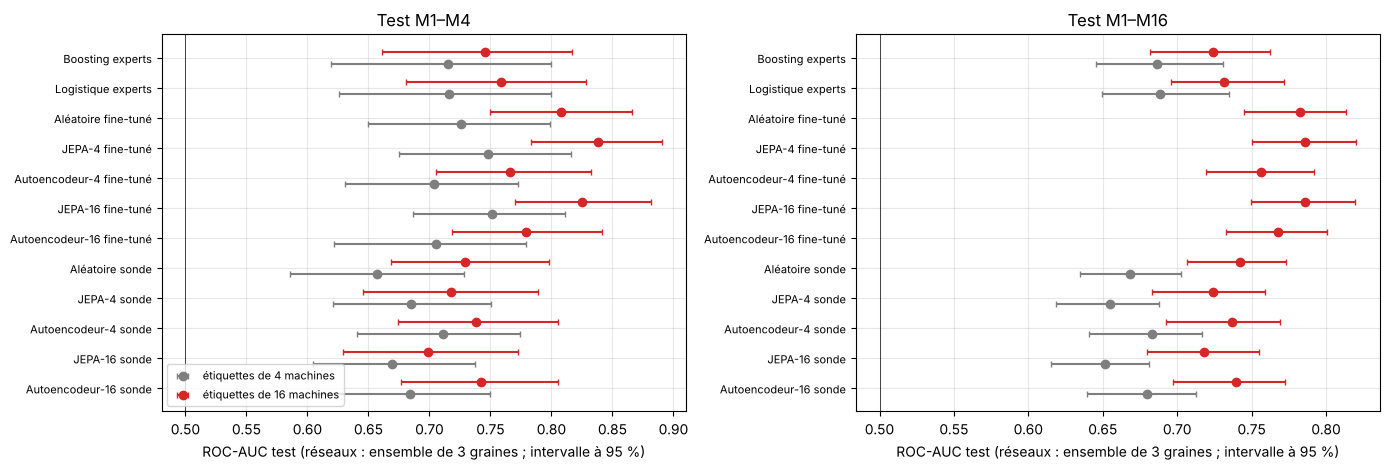

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
order = ["Boosting experts", "Logistique experts"] + [f"{n} {t}" for t in ["fine-tuné", "sonde"] for n in ENC_NAMES]
for ax, tn in zip(axes, TE):
    for j, k in enumerate(LABELS):
        r_ = RESULTS[(RESULTS.test == tn) & (RESULTS.etiquettes == k)].set_index("methode").reindex(order)
        y_ = np.arange(len(order)) + (0.2 if k == "4" else -0.2)
        ax.errorbar(r_.roc_auc, y_, xerr=[r_.roc_auc - r_.ic95_bas, r_.ic95_haut - r_.roc_auc], fmt="o", color="C7" if k == "4" else "C3", capsize=2,
                    label=f"étiquettes de {k} machines")
    ax.set_yticks(np.arange(len(order))); ax.set_yticklabels(order, fontsize=8); ax.invert_yaxis(); ax.axvline(0.5, color="k", lw=0.5)
    ax.set_title(f"Test {tn}"); ax.set_xlabel("ROC-AUC test (réseaux : ensemble de 3 graines ; intervalle à 95 %)")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(RES / "comparaison_etiquettes.png", dpi=90); plt.show()

### 8.1 Écarts par graine

À graine égale et avec le même jeu d'étiquettes, deux réseaux ont la même initialisation de tête et les mêmes tirages de fine-tuning. Pour les écarts **16 − 4 machines étiquetées** (et H10), seules la graine et l'initialisation de tête sont communes : les lots, l'époque retenue (validation M1–M16 contre M1–M4) et le nombre de passages par fenêtre étiquetée diffèrent.

Les écarts 16 − 4 machines ne sont calculés que sur le **test M1–M4** : c'est le seul qui isole l'effet du nombre de machines étiquetées. Sur M1–M16, les modèles à 16 machines ont en plus vu des pannes des machines du test (une autre année), ce que les modèles à 4 machines n'ont pas pu faire.

In [11]:
def ecart(a, b, k, tn, ka=None):
    """AUC(a, étiquettes ka ou k) − AUC(b, étiquettes k) graine par graine, ou contre le boosting (modèle unique) si b le demande."""
    ka = ka or k; d = []
    for s_ in SEEDS:
        if (a, ka, s_) not in SCORES or np.isnan(SCORES[(a, ka, s_)][TE[tn]]).any(): return None
        pb = SCORES[(b, k, None)] if (b, k, None) in SCORES else SCORES.get((b, k, s_))
        if pb is None or np.isnan(pb[TE[tn]]).any(): return None
        d.append(auc_on(SCORES[(a, ka, s_)], tn) - auc_on(pb, tn))
    return dict(moyenne=np.mean(d), par_graine=" / ".join(f"{x:+.3f}" for x in d), graines_positives=f"{sum(x > 0 for x in d)}/{len(d)}")
ec_rows = []
for tn in TE:
    for k in LABELS:
        for tete in ["fine-tuné", "sonde"]:
            for a, b in [("JEPA-16", "Aléatoire"), ("JEPA-16", "JEPA-4"), ("JEPA-16", "Autoencodeur-16"), ("Autoencodeur-16", "Aléatoire")]:
                r_ = ecart(f"{a} {tete}", f"{b} {tete}", k, tn)
                if r_: ec_rows.append(dict(comparaison=f"{a} − {b} ({tete})", etiquettes=k, test=tn, **r_))
    if tn != "M1–M4": continue           # seul test qui isole le nombre de machines étiquetées
    for meth in ["Boosting experts", "Logistique experts"] + [f"{n} sonde" for n in ENC_NAMES] + ([f"{n} fine-tuné" for n in ENC_NAMES] if REUSE_OK else []):
        if (meth, "4", None) in SCORES:      # modèle unique
            d_ = auc_on(SCORES[(meth, "16", None)], tn) - auc_on(SCORES[(meth, "4", None)], tn); r_ = dict(moyenne=d_, par_graine=f"{d_:+.3f}", graines_positives="")
        else: r_ = ecart(meth, meth, "4", tn, ka="16")
        if r_: ec_rows.append(dict(comparaison=f"{meth} : 16 − 4 machines étiquetées", etiquettes="16 vs 4", test=tn, **r_))
EC = pd.DataFrame(ec_rows); EC.to_csv(RES / "ecarts_par_graine.csv", index=False)
EC.round(3)

,comparaison,etiquettes,test,moyenne,par_graine,graines_positives
0,JEPA-16 − Aléatoire (fine-tuné),4,M1–M4,0.003,+0.038 / -0.015 / -0.012,1/3
1,JEPA-16 − JEPA-4 (fine-tuné),4,M1–M4,-0.000,+0.021 / +0.021 / -0.043,2/3
2,JEPA-16 − Autoencodeur-16 (fine-tuné),4,M1–M4,0.030,+0.028 / +0.018 / +0.042,3/3
3,Autoencodeur-16 − Aléatoire (fine-tuné),4,M1–M4,-0.026,+0.009 / -0.033 / -0.055,1/3
4,JEPA-16 − Aléatoire (sonde),4,M1–M4,0.005,+0.013 / -0.011 / +0.014,2/3
5,JEPA-16 − JEPA-4 (sonde),4,M1–M4,-0.009,+0.009 / -0.008 / -0.029,1/3
6,JEPA-16 − Autoencodeur-16 (sonde),4,M1–M4,-0.018,-0.022 / +0.013 / -0.043,1/3
7,Autoencodeur-16 − Aléatoire (sonde),4,M1–M4,0.023,+0.036 / -0.024 / +0.057,2/3
8,JEPA-16 − Aléatoire (fine-tuné),16,M1–M4,0.004,+0.012 / -0.004 / +0.003,2/3
9,JEPA-16 − JEPA-4 (fine-tuné),16,M1–M4,-0.019,-0.023 / +0.002 / -0.035,1/3


### 8.2 Par type de dégradation (test M1–M16, étiquettes de 16 machines)

ROC-AUC des fenêtres positives d'un type donné contre toutes les fenêtres négatives du test (réseaux : ensemble des graines).

In [12]:
tn = "M1–M16"; yt = yE[TE[tn]]; neg = yt == 0; typ = E.type_suivant.to_numpy()[TE[tn]]; rows = []
for meth in ["Boosting experts", "Aléatoire fine-tuné", "JEPA-16 fine-tuné", "Autoencodeur-16 fine-tuné", "JEPA-16 sonde", "Autoencodeur-16 sonde"]:
    p = SCORES[(meth, "16", None)] if (meth, "16", None) in SCORES else np.mean([rank(SCORES[(meth, "16", s_)]) for s_ in SEEDS], 0)
    sc = p[TE[tn]]; row = {"methode": meth}
    for ft in TYPES:
        pos = (yt == 1) & (typ == ft)
        row[ft] = roc_auc_score(np.r_[np.ones(pos.sum()), np.zeros(neg.sum())], np.r_[sc[pos], sc[neg]]) if pos.sum() else np.nan
    rows.append(row)
pd.DataFrame(rows).set_index("methode").round(3)

,refroidissement,roulement,courroie,pneumatique,electrique
methode,,,,,
Boosting experts,0.613,0.881,0.770,0.913,0.461
Aléatoire fine-tuné,0.853,0.818,0.847,0.891,0.473
JEPA-16 fine-tuné,0.842,0.835,0.828,0.903,0.498
Autoencodeur-16 fine-tuné,0.881,0.718,0.846,0.874,0.476
JEPA-16 sonde,0.860,0.725,0.698,0.794,0.463
Autoencodeur-16 sonde,0.905,0.729,0.683,0.827,0.494


## 9. Hypothèses et conclusions

Hypothèses copiées mot pour mot de `flotte_non_etiquetee/LISEZMOI_FLOTTE.md` (section « Expérience 2 »), écrites **avant** l'exécution, et confrontées ici sans les réécrire :
- **H10.** Avec les étiquettes des 16 machines au lieu de 4, le boosting expert et JEPA-16 fine-tuné (pour chaque graine) font mieux sur le test M1–M4.
- **H11.** Avec les étiquettes des 16 machines, JEPA-16 fine-tuné bat l'encodeur aléatoire fine-tuné pour chaque graine, sur le test M1–M16.
- **H12.** Avec les étiquettes des 16 machines, JEPA-16 fine-tuné bat le boosting expert sur le test M1–M16 : la moyenne des ROC-AUC des 3 graines dépasse celle du boosting. L'ensemble des 3 graines est rapporté en complément.
- **H13.** JEPA-16 contre autoencodeur-16 fine-tunés, étiquettes des 16 machines, test M1–M16 : pas d'hypothèse de sens ; on rapporte l'écart par graine.

In [13]:
TOUTES = f"{len(SEEDS)}/{len(SEEDS)}"
def R(meth, k, tn):
    r_ = RESULTS[(RESULTS.methode == meth) & (RESULTS.etiquettes == k) & (RESULTS.test == tn)]
    assert len(r_) == 1, (meth, k, tn); return r_.iloc[0]
b4, b16 = R("Boosting experts", "4", "M1–M4"), R("Boosting experts", "16", "M1–M4")
if REUSE_OK:
    j10 = ecart("JEPA-16 fine-tuné", "JEPA-16 fine-tuné", "4", "M1–M4", ka="16")
    ok10 = (b16.roc_auc > b4.roc_auc) and j10["graines_positives"] == TOUTES
    print(f"H10 : test M1–M4, boosting {b4.roc_auc:.3f} -> {b16.roc_auc:.3f} ; JEPA-16 fine-tuné 16 − 4 machines {j10['moyenne']:+.3f} (par graine {j10['par_graine']})"
          f" -> {'confirmée' if ok10 else 'non confirmée'}")
else: print("H10 non évaluable (réglages de fine-tuning différents des fine-tunings repris)")
r11 = ecart("JEPA-16 fine-tuné", "Aléatoire fine-tuné", "16", "M1–M16")
print(f"H11 : test M1–M16, JEPA-16 − aléatoire fine-tunés = {r11['moyenne']:+.3f} (par graine {r11['par_graine']}) -> {'confirmée' if r11['graines_positives'] == TOUTES else 'non confirmée'}")
j12, b12 = R("JEPA-16 fine-tuné", "16", "M1–M16"), R("Boosting experts", "16", "M1–M16")
print(f"H12 : test M1–M16, JEPA-16 fine-tuné moyenne des graines {j12.moyenne_graines:.3f} (graines {j12.par_graine} ; ensemble {j12.roc_auc:.3f} [{j12.ic95_bas:.2f} ; {j12.ic95_haut:.2f}])"
      f" contre boosting {b12.roc_auc:.3f} [{b12.ic95_bas:.2f} ; {b12.ic95_haut:.2f}], écart {j12.moyenne_graines - b12.roc_auc:+.3f}"
      f" -> {'confirmée' if j12.moyenne_graines > b12.roc_auc else 'non confirmée'} (handicap connu du lissage des fine-tunés ≈ 0,007)")
# Sensibilité, hors pré-enregistrement : sorties brutes du fine-tuning relissées machine par machine avec la même demi-vie (≈ 8,3 h, soit span = 12 fenêtres de 2 h),
# mais en tenant compte du temps écoulé entre deux fenêtres évaluées (le signal décroît pendant les périodes exclues, comme pour le boosting).
HL = pd.Timedelta(hours=2 * math.log(0.5) / math.log(11 / 13))
def smooth_time(raw):
    s_ = pd.Series(raw.astype(float), index=E.index)
    return pd.concat([s_[E.machine == m].ewm(halflife=HL, times=E.time[E.machine == m]).mean() for m in ALL]).loc[E.index].to_numpy()
sens12 = [auc_on(smooth_time(FT[("JEPA-16", "16", s_)][3]), "M1–M16") for s_ in SEEDS]
print(f"     sensibilité (lissage tenant compte du temps) : JEPA-16 fine-tuné moyenne des graines {np.mean(sens12):.3f} (graines {' / '.join(f'{x:.3f}' for x in sens12)}),"
      f" écart au boosting {np.mean(sens12) - b12.roc_auc:+.3f}")
r13 = ecart("JEPA-16 fine-tuné", "Autoencodeur-16 fine-tuné", "16", "M1–M16")
print(f"H13 : test M1–M16, JEPA-16 − autoencodeur-16 fine-tunés = {r13['moyenne']:+.3f} (par graine {r13['par_graine']})")

H10 : test M1–M4, boosting 0.715 -> 0.745 ; JEPA-16 fine-tuné 16 − 4 machines +0.083 (par graine +0.057 / +0.095 / +0.096) -> confirmée
H11 : test M1–M16, JEPA-16 − aléatoire fine-tunés = -0.001 (par graine +0.001 / -0.007 / +0.004) -> non confirmée
H12 : test M1–M16, JEPA-16 fine-tuné moyenne des graines 0.765 (graines 0.763 / 0.768 / 0.765 ; ensemble 0.786 [0.75 ; 0.82]) contre boosting 0.724 [0.68 ; 0.76], écart +0.041 -> confirmée (handicap connu du lissage des fine-tunés ≈ 0,007)


     sensibilité (lissage tenant compte du temps) : JEPA-16 fine-tuné moyenne des graines 0.778 (graines 0.775 / 0.781 / 0.778), écart au boosting +0.054
H13 : test M1–M16, JEPA-16 − autoencodeur-16 fine-tunés = +0.013 (par graine +0.013 / +0.025 / +0.001)


### 9.1 Compléments (hors pré-enregistrement, ajoutés après la première exécution)

**Boosting avec une grille de réglages élargie.** Avec 16 machines étiquetées, le boosting retient le réglage le plus prudent de sa petite grille (4 combinaisons) : la grille n'encadre donc peut-être pas son meilleur réglage. On le réentraîne avec 12 combinaisons (qui contiennent les 4 d'origine), choisies de la même façon sur la validation.

**Écarts appariés.** Intervalle à 95 % de l'écart d'AUC entre deux méthodes, par bootstrap par blocs (machine × semaine) en tirant **les mêmes blocs pour toutes les méthodes comparées**, ce que ne font pas les intervalles séparés de la section 8. Réseaux : moyenne des AUC des 3 graines (un modèle seul, comme dans H12) ; lissage pré-enregistré. Sur le test M1–M4, on mesure aussi le gain 16 − 4 machines étiquetées et la « différence de différences » (écart JEPA-16 fine-tuné − boosting avec 16 machines, moins le même écart avec 4 machines).

In [14]:
gbm_grid_large = [(f"lr={lr}, {it} arbres, feuilles={ml}", (lambda lr=lr, it=it, ml=ml: HistGradientBoostingClassifier(learning_rate=lr, max_iter=it, max_leaf_nodes=ml, l2_regularization=1.0, random_state=0)))
                  for lr, it in [(0.01, 1000), (0.03, 300), (0.03, 1000), (0.1, 300)] for ml in (7, 15, 31)]
BL = "Boosting experts (grille élargie)"
for k in LABELS:
    p, hp, a = fit_select(gbm_grid_large, XF, TR[k], VA[k]); SCORES[(BL, k, None)] = p
    print(f"étiquettes {k:>2} machines  {BL} : {hp}, AUC validation {a:.3f} ; test M1–M4 {auc_on(p, 'M1–M4'):.3f}, test M1–M16 {auc_on(p, 'M1–M16'):.3f}")

def preds(meth, k, tn): return [SCORES[(meth, k, None)][TE[tn]]] if (meth, k, None) in SCORES else [SCORES[(meth, k, s_)][TE[tn]] for s_ in SEEDS]
def auc_mean(ps, tn, idx=None):
    yt = yE[TE[tn]]; return np.mean([roc_auc_score(yt, p_) if idx is None else roc_auc_score(yt[idx], p_[idx]) for p_ in ps])
def apparie(label, tn, *pairs):
    """(AUC(a) − AUC(b)) [− (AUC(c) − AUC(d))], intervalle à 95 % par bootstrap par blocs avec les mêmes blocs pour toutes les méthodes"""
    P = [preds(m_, k_, tn) for m_, k_ in pairs]
    f = lambda idx: (auc_mean(P[0], tn, idx) - auc_mean(P[1], tn, idx)) - ((auc_mean(P[2], tn, idx) - auc_mean(P[3], tn, idx)) if len(P) == 4 else 0)
    bs = np.array([f(i) for i in BOOT[tn]])
    return dict(test=tn, comparaison=label, ecart=f(None), ic95_bas=np.percentile(bs, 2.5), ic95_haut=np.percentile(bs, 97.5), part_bootstrap_positive=(bs > 0).mean())
FT16, BO = "JEPA-16 fine-tuné", "Boosting experts"
COMP = [("M1–M16", f"{FT16} − boosting (16 machines étiquetées)", (FT16, "16"), (BO, "16")),
        ("M1–M16", f"{FT16} − boosting grille élargie (16)", (FT16, "16"), (BL, "16")),
        ("M1–M16", "Aléatoire fine-tuné − boosting (16)", ("Aléatoire fine-tuné", "16"), (BO, "16")),
        ("M1–M16", f"{FT16} − Aléatoire fine-tuné (16)", (FT16, "16"), ("Aléatoire fine-tuné", "16")),
        ("M1–M16", "JEPA-4 fine-tuné − Aléatoire fine-tuné (16)", ("JEPA-4 fine-tuné", "16"), ("Aléatoire fine-tuné", "16")),
        ("M1–M16", f"{FT16} − Autoencodeur-16 fine-tuné (16)", (FT16, "16"), ("Autoencodeur-16 fine-tuné", "16")),
        ("M1–M4", "Boosting : 16 − 4 machines étiquetées", (BO, "16"), (BO, "4")),
        ("M1–M4", "Boosting grille élargie : 16 − 4", (BL, "16"), (BL, "4")),
        ("M1–M4", "Logistique experts : 16 − 4", ("Logistique experts", "16"), ("Logistique experts", "4")),
        ("M1–M4", "JEPA-16 sonde : 16 − 4", ("JEPA-16 sonde", "16"), ("JEPA-16 sonde", "4")),
        ("M1–M4", "JEPA-4 fine-tuné − Aléatoire fine-tuné (16)", ("JEPA-4 fine-tuné", "16"), ("Aléatoire fine-tuné", "16")),
        ("M1–M4", f"{FT16} − boosting (16)", (FT16, "16"), (BO, "16"))]
if REUSE_OK:      # comparaisons qui utilisent les fine-tunings repris sur 4 machines
    COMP += [("M1–M4", f"{FT16} : 16 − 4", (FT16, "16"), (FT16, "4")), ("M1–M4", "Aléatoire fine-tuné : 16 − 4", ("Aléatoire fine-tuné", "16"), ("Aléatoire fine-tuné", "4")),
             ("M1–M4", f"{FT16} − boosting (4)", (FT16, "4"), (BO, "4")),
             ("M1–M4", f"({FT16} − boosting) avec 16 machines, moins avec 4", (FT16, "16"), (BO, "16"), (FT16, "4"), (BO, "4"))]
APP = pd.DataFrame([apparie(lab_, tn_, *pr_) for tn_, lab_, *pr_ in COMP]); APP.to_csv(RES / "ecarts_apparies.csv", index=False)
print(f"Durée totale : {(time.time() - t_start) / 60:.0f} min")
APP.round(3)

étiquettes  4 machines  Boosting experts (grille élargie) : lr=0.03, 1000 arbres, feuilles=15, AUC validation 0.686 ; test M1–M4 0.715, test M1–M16 0.682


étiquettes 16 machines  Boosting experts (grille élargie) : lr=0.03, 300 arbres, feuilles=7, AUC validation 0.761 ; test M1–M4 0.756, test M1–M16 0.730


Durée totale : 10 min


,test,comparaison,ecart,ic95_bas,ic95_haut,part_bootstrap_positive
0,M1–M16,JEPA-16 fine-tuné − boosting (16 machines étiq...,0.041,0.008,0.075,0.987
1,M1–M16,JEPA-16 fine-tuné − boosting grille élargie (16),0.035,0.002,0.067,0.977
2,M1–M16,Aléatoire fine-tuné − boosting (16),0.042,0.005,0.077,0.987
3,M1–M16,JEPA-16 fine-tuné − Aléatoire fine-tuné (16),-0.001,-0.012,0.009,0.457
4,M1–M16,JEPA-4 fine-tuné − Aléatoire fine-tuné (16),0.003,-0.010,0.014,0.710
5,M1–M16,JEPA-16 fine-tuné − Autoencodeur-16 fine-tuné ...,0.013,-0.002,0.030,0.947
6,M1–M4,Boosting : 16 − 4 machines étiquetées,0.030,-0.022,0.078,0.913
7,M1–M4,Boosting grille élargie : 16 − 4,0.041,-0.014,0.103,0.917
8,M1–M4,Logistique experts : 16 − 4,0.042,-0.002,0.079,0.973
9,M1–M4,JEPA-16 sonde : 16 − 4,0.029,-0.010,0.069,0.937


### 9.2 Conclusions (rédigées après exécution)

**En bref** : avec 4 fois plus de pannes étiquetées, les réseaux fine-tunés font nettement mieux (+0,07 à +0,10 d'AUC sur le test M1–M4) et sont alors devant le boosting expert sur le test M1–M16 (JEPA-16 fine-tuné : +0,041, intervalle apparié [+0,008 ; +0,075] ; que ce passage devant le boosting vienne des étiquettes en plus est probable, mais pas établi). **Ce n'est pas grâce au pré-entraînement JEPA** : le même réseau parti de poids aléatoires fait aussi bien. Le pré-entraînement n'utilise pas d'étiquettes, et ce qu'il apprend n'apporte toujours rien de mesurable face à des poids aléatoires sur le test M1–M16 (écart −0,001, intervalle apparié [−0,012 ; +0,009]).

1. **H10 confirmée : les pannes étiquetées de la flotte améliorent aussi les prédictions sur les 4 machines d'origine (test M1–M4).** Le boosting passe de 0,715 à 0,745 et JEPA-16 fine-tuné gagne +0,083 (+0,057 / +0,095 / +0,096 selon la graine). Le gain n'a pas la même solidité partout (écarts appariés, section 9.1) :
   - réseaux fine-tunés : entre +0,07 et +0,10 en moyenne des graines, et chaque graine gagne (de +0,04 à +0,12) ; intervalle apparié [+0,052 ; +0,108] pour JEPA-16 et [+0,039 ; +0,131] pour l'aléatoire ;
   - sondes : entre +0,03 et +0,08 en moyenne des graines (de +0,02 à +0,12 selon la graine) ;
   - boosting et logistique sur caractéristiques expertes : +0,03 et +0,04, des écarts du même ordre que l'incertitude (intervalles appariés [−0,022 ; +0,078] et [−0,002 ; +0,079]).

   Les pannes d'autres machines du même type (variantes à ±10 %) aident donc à prédire celles des 4 machines d'origine, nettement pour les réseaux fine-tunés. Ceux-ci semblent en profiter plus que le boosting (+0,053 de plus pour JEPA-16, intervalle [−0,005 ; +0,114] : probable, pas établi).
2. **H11 non confirmée : le pré-entraînement JEPA ne fait pas mieux que des poids aléatoires.** Sur le test M1–M16, JEPA-16 et l'encodeur aléatoire fine-tunés sont à égalité : −0,001 (+0,001 / −0,007 / +0,004), intervalle apparié [−0,012 ; +0,009]. JEPA-4 non plus : 0,769 contre 0,766 en moyenne des graines (+0,003 [−0,010 ; +0,014], un écart minime qui change de signe selon la graine). Seul écart en faveur de JEPA : sur le test M1–M4, JEPA-4 fine-tuné est un peu devant l'aléatoire (+0,023 [+0,002 ; +0,045], 2 graines sur 3) ; c'est une comparaison non pré-enregistrée, repérée parmi beaucoup d'autres, à ne pas surinterpréter. Sur l'encodeur gelé, c'est pire : les sondes JEPA sont les plus faibles des sondes (sonde JEPA-16 : 0,685 contre 0,718 pour la sonde aléatoire en moyenne des graines, en dessous pour chacune des 3 graines).
3. **H12 confirmée : avec les étiquettes des 16 machines, JEPA-16 fine-tuné bat le boosting expert sur le test M1–M16, mais pas grâce au pré-entraînement : l'encodeur aléatoire fine-tuné fait autant.** JEPA-16 fine-tuné fait 0,765 en moyenne des graines contre 0,724 pour le boosting (+0,041, intervalle apparié [+0,008 ; +0,075]) ; l'ensemble des 3 graines fait 0,786 [0,75 ; 0,82]. L'écart tient face à un boosting mieux réglé (12 réglages au lieu de 4 : 0,730, écart +0,035 [+0,002 ; +0,067]) et passe à +0,054 avec un lissage qui tient compte du temps entre deux fenêtres. L'encodeur aléatoire fine-tuné bat le boosting d'autant : 0,766 contre 0,724, soit +0,042 [+0,005 ; +0,077].

   Avec les étiquettes de 4 machines, sur le test M1–M4, aucun réseau ne dépassait le boosting en moyenne des graines (au mieux 0,710 contre 0,715) ; seuls 3 fine-tunings sur 15 pris isolément (jusqu'à 0,735) et les ensembles de 3 graines de JEPA-16, JEPA-4 et de l'aléatoire fine-tunés (0,73 à 0,75) le dépassaient. Avec les étiquettes de 16 machines, sur ce même test, JEPA-16 fine-tuné fait 0,793 et l'aléatoire fine-tuné 0,789 en moyenne des graines, contre 0,745 pour le boosting. Que ce passage devant le boosting vienne des étiquettes en plus est donc probable, mais pas établi (différence des écarts +0,053 [−0,005 ; +0,114]).

   Par type de panne (test M1–M16, ensembles de 3 graines, sans intervalle) : les fine-tunés sont nettement devant sur le refroidissement (0,84 à 0,88 contre 0,61 pour le boosting) et un peu sur la courroie (0,83 à 0,85 contre 0,77) ; le boosting reste devant sur le roulement (0,88 contre 0,72 à 0,83) et, de peu, sur le pneumatique (0,91 contre 0,87 à 0,90) ; personne ne prédit les pannes électriques (0,46 à 0,50). L'avantage global des réseaux vient donc surtout du refroidissement (lecture du tableau).
4. **H13 (pas de sens prévu) : JEPA-16 fine-tuné fait peut-être un peu mieux que l'autoencodeur-16 fine-tuné**, +0,013 en moyenne (+0,013 / +0,025 / +0,001), mais l'intervalle apparié [−0,002 ; +0,030] contient 0 : l'écart n'est pas établi. Comme dans les notebooks précédents, c'est l'inverse sur l'encodeur gelé (sonde JEPA-16 − sonde autoencodeur-16 = −0,029 en moyenne, en dessous pour chacune des 3 graines). Aucun des deux ne dépasse l'encodeur aléatoire fine-tuné : l'autoencodeur-16 fait même un peu moins bien (−0,014).

**Ce qu'on peut en retenir.** Sur ces données synthétiques, ce qui fait progresser la prédiction, ce sont les pannes étiquetées, y compris celles d'autres machines du même type, et non le pré-entraînement JEPA. Pour de vraies machines, c'est une piste à vérifier, pas une conclusion : ici, les étiquettes sont la vérité exacte du simulateur (dates exactes des pannes et des interventions), les 12 machines ajoutées sont des variantes à ±10 % des 4 premières, et le coût de la qualification n'est pas mesuré. Sous ces réserves, qualifier dans la GMAO les pannes de toute la flotte, avec des dates fiables, semble plus utile que d'ajouter des données de capteurs sans étiquettes (qui n'avaient rien changé dans `F-JEPA_flotte`). Pour JEPA, les pistes restent celles du notebook précédent, non testées ici : changer ce que le pré-entraînement doit prédire (par exemple sur un contexte de plusieurs jours, pour que la dérive d'une dynamique devienne la chose à prédire), ou vérifier qu'un pré-entraînement 4 fois plus long sur les 16 machines ne change rien.

**Limites.**
- Données inventées, et les 16 machines sortent du même simulateur : c'est un cas favorable au transfert entre machines, et au pré-entraînement, qui n'en profite pourtant pas.
- Dans les comparaisons sur lesquelles reposent ces conclusions (16 contre 4 machines étiquetées sur le test M1–M4, et modèles à 16 machines sur le test M1–M16), les machines testées ont toujours leurs propres pannes des années précédentes étiquetées. Le résultat montre donc que les pannes d'autres machines aident à prédire une machine **déjà étiquetée** ; aucun résultat n'isole le cas d'une machine dont aucune panne n'a été qualifiée (nouvelle machine, autre site).
- 3 graines seulement. Les verdicts H10 à H12, et l'écart rapporté pour H13 (sans sens prévu), viennent du calcul pré-enregistré ; le boosting mieux réglé, les écarts appariés (9.1) et le lissage tenant compte du temps ont été ajoutés après coup.
- Même nombre de pas de fine-tuning qu'avec 4 machines : la meilleure époque est la dernière pour 10 fine-tunings sur 15. Un fine-tuning plus long ferait sans doute mieux, pour tous les réseaux, aléatoire compris (supposé, non testé).
- Le boosting mieux réglé retient encore un réglage au bord de sa grille (7 feuilles, le minimum essayé) : un réglage plus poussé pourrait encore réduire un peu l'écart avec les réseaux (non testé).
- Calcul complet, mesuré lors de la première exécution : 162 min, soit environ 2 h 40, sur 4 cœurs CPU (sondes : 4 à 5 min par encodeur et par graine ; fine-tunings : 5,5 à 6,5 min chacun ; 15 de chaque). Cette version relit les sondes et les fine-tunings enregistrés (`results_flotte_etiquetee/`), d'où environ 10 min d'exécution.